In [1]:
from itertools import product
import pickle
from tqdm import tqdm, trange

import numpy as np
from numpy.linalg import eigh
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Ellipse
from corner import corner as corner_plot

from scipy import special, stats
from scipy.stats import gaussian_kde, chi2
from scipy.interpolate import RegularGridInterpolator

import os

from local_utils import delaunaytor
from popsummary.popresult import PopulationResult
from astropy.cosmology import Planck15
from astropy import units as u
import popsummary
import plot_funcs_bbh_mass as pf


plt.style.use("tableau-colorblind10")
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.size"] = 14
plt.rcParams["text.usetex"] = True

In [2]:
def q_flat(x):
    ans=1/(5-(-15))

    return ans


def kl_divergence_kde_p_known_q(p_samples, q_pdf, base=np.e, bandwidth='scott'):
    """
    Estimate KL divergence D_KL(P || Q) where:
      - P is only known via samples (estimated with KDE)
      - Q is known analytically via q_pdf(x)
    
    Parameters:
        p_samples (array): 1D array of samples from P
        q_pdf (function): function that returns q(x) given x
        base (float): logarithm base (e.g., np.e or 2)
        bandwidth: bandwidth for KDE (default: 'scott')
    
    Returns:
        float: Estimated KL divergence D_KL(P || Q)
    """
    p_samples = np.asarray(p_samples)
    kde = gaussian_kde(p_samples, bw_method=bandwidth)

    # Evaluate both p(x) and q(x) at the sample points
    p_kde_vals = kde(p_samples)
    q_vals = q_pdf(p_samples)

    # Avoid division by zero or log(0)
    epsilon = 1e-12
    p_kde_vals = np.clip(p_kde_vals, epsilon, None)
    q_vals = np.clip(q_vals, epsilon, None)

    log_ratio = np.log(p_kde_vals / q_vals)
    kl = np.mean(log_ratio)

    return kl / np.log(base)


def kl_divergence_kde(p_samples, q_samples, base=np.e, bandwidth='scott'):
    """
    Estimate delta divergence D_delta(P || Q) where:
      - P is known via samples (estimated with KDE)
      - Q is known via samples (estimated with KDE)
    
    Parameters:
        p_samples (array): 1D array of samples from P
        q_samples (array): 1D array of samples from Q
        base (float): logarithm base (e.g., np.e or 2)
        bandwidth: bandwidth for KDE (default: 'scott')
    
    Returns:
        float: Estimated delta divergence D_delta(P || Q)
    """
    p_samples = np.asarray(p_samples)
    kde_p = gaussian_kde(p_samples, bw_method=bandwidth)

    q_samples = np.asarray(q_samples)
    kde_q = gaussian_kde(q_samples, bw_method=bandwidth)

    # Evaluate both p(x) and q(x) at the sample points
    p_kde_vals = kde_p(p_samples)
    q_kde_vals = kde_q(p_samples)

    # Avoid division by zero or log(0)
    epsilon = 1e-12
    p_kde_vals = np.clip(p_kde_vals, epsilon, None)
    q_kde_vals = np.clip(q_kde_vals, epsilon, None)

    log_ratio = np.log(p_kde_vals / q_kde_vals)
    delta = np.mean(log_ratio)

    return delta / np.log(base)

In [3]:
def smoothing_function(m1, lower, sig):
    smooth = np.zeros_like(m1)
    in_smooth = np.logical_and(m1 >= lower, m1 < lower+sig)
    f = lambda m: np.exp(sig/m + sig/(m-sig))
    smooth[in_smooth] = 1 /(1 + f(m1[in_smooth]-lower))
    smooth[m1>=lower+sig]=1
    return smooth


def power_law_peak(m1, gaussian_params, powlaw_params, smooth_params):
    gauss_pdf = stats.norm(
            loc=gaussian_params[1], scale=gaussian_params[2]
        ).pdf(m1)

    indx, lower, upper = powlaw_params
    norm = (upper**(1 - indx) - lower**(1 - indx)) / (1 - indx)
    powlaw_pdf = m1**(-indx) / norm
    out_bounds = np.logical_or(m1 < lower, m1 > upper)
    powlaw_pdf[out_bounds] = 0

    weight = gaussian_params[0]
    result = weight * gauss_pdf + (1 - weight) * powlaw_pdf

    smooth = smoothing_function(m1, lower, smooth_params)
    return result*smooth

## Use LVK population analysis results as `true' population

In [4]:
gwtc4 = '/home/tristan-bruel/Documents/Science/LVK/gwtc4'
zeval = 0.2
color1 = '#FE6100'

gwtc4_pop_file = os.path.join(gwtc4, 'data_release/BBHMassSpinRedshift_BrokenPowerLawTwoPeaks_GaussianComponentSpins_PowerLawRedshift.h5')

bptp_o4 = popsummary.popresult.PopulationResult(gwtc4_pop_file)
bptp_m1, bptp_m1_pdfs = pf.get_params(bptp_o4, 'mass_1', rate=True)
bptp_q, bptp_q_pdfs = pf.get_params(bptp_o4, 'mass_ratio')
z_list_gwtc4, R_z_gwtc4 = bptp_o4.get_rates_on_grids('redshift')
z_list_gwtc4 = z_list_gwtc4[0]
kappas, R_0 = bptp_o4.get_hyperparameter_samples(hyperparameters=['lamb','rate']).T

opening existing popsummary file: /home/tristan-bruel/Documents/Science/LVK/gwtc4/data_release/BBHMassSpinRedshift_BrokenPowerLawTwoPeaks_GaussianComponentSpins_PowerLawRedshift.h5


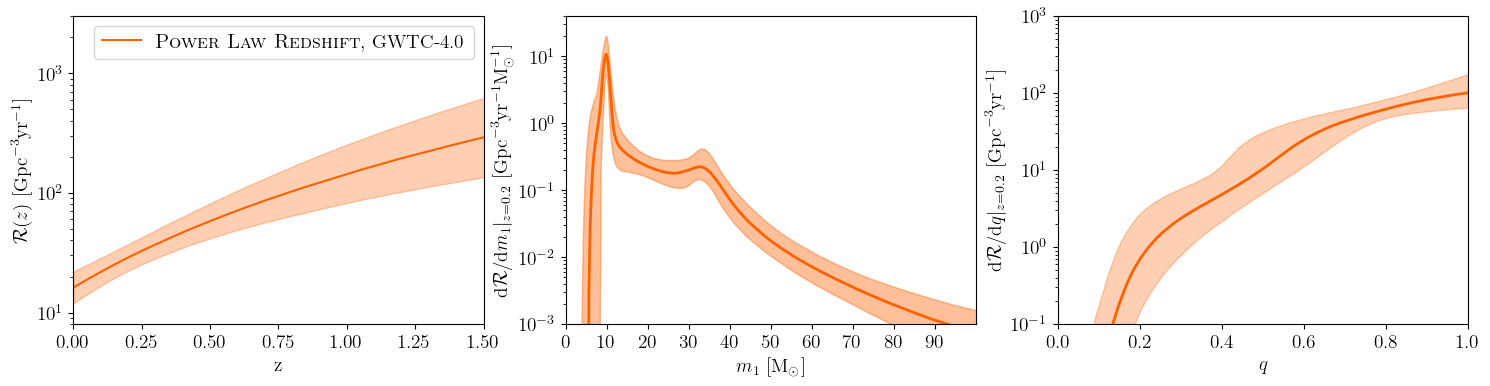

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18,4))

# Merger rate with redshift #
ax = axes[0]
ax.fill_between(z_list_gwtc4, np.percentile(R_z_gwtc4, 5, axis=0), np.percentile(R_z_gwtc4, 95, axis=0), 
                color=color1, alpha=0.3,
               )
ax.plot(z_list_gwtc4, np.percentile(R_z_gwtc4, 50, axis=0), 
        color=color1, 
        label='\\textsc{Power Law Redshift}, GWTC-4.0',
       )

ax.set_xlabel('z')
ax.set_xlim(xmin=0, xmax=1.5)
ax.set_ylabel(r'$\mathcal{R}(z)\ [\mathrm{Gpc}^{-3} \mathrm{yr}^{-1}]$')
ax.set_yscale('log')
ax.set_ylim(ymin=8, ymax=3e3)
ax.legend()

# Primary mass #
ax = axes[1]
pf.plot_90CI(ax, bptp_m1, bptp_m1_pdfs, 
             color=color1,  fill_alpha=0.4,
             label=r'\textsc{Broken Power Law + 2 Peaks}, \textsc{GWTC-4.0}',
            )
ax.set_xlabel(r'$m_1\ [\mathrm{M}_\odot]$')
ax.set_xlim(xmin=0, xmax=100)
ax.set_xticks(np.linspace(0,90,10))
ax.set_ylabel(r'$\mathrm{d}\mathcal{R}/\mathrm{d}m_1 |_{z=0.2}\ [\mathrm{Gpc}^{-3} \mathrm{yr}^{-1} \mathrm{M}_\odot^{-1}]$')
ax.set_yscale('log')
ax.set_ylim(ymin=1e-3, ymax=4e1)
#ax.legend(loc='upper right', frameon=False)

# Mass ratio #
ax = axes[2]
pf.plot_90CI(ax, bptp_q, bptp_q_pdfs, 
             color=color1, 
             label=r'\textsc{Broken Power Law + 2 Peaks}, \textsc{GWTC-4.0}',
            )
ax.set_xlabel(r'$q$')
ax.set_xlim(xmin=0, xmax=1)
ax.set_xticks(np.linspace(0,1,6))
ax.set_ylabel(r'$\mathrm{d}\mathcal{R}/\mathrm{d}q |_{z=0.2}\ [\mathrm{Gpc}^{-3} \mathrm{yr}^{-1}]$')
ax.set_yscale('log')
ax.set_ylim(ymin=1e-1, ymax=1e3)
#ax.legend(loc='upper left', frameon=False)


plt.show()
plt.close()

In [6]:
zeval=0.2
print('R0 x (1+z)**k, R(z=%.1f), integral dR/dm1, integral dR/dq' %zeval)
for ind in(np.random.randint(0,len(kappas),3)):
    Rzeval = interp1d(z_list_gwtc4, R_z_gwtc4[ind,:], fill_value='extrapolate')(zeval)
    int_dRdm1 = np.trapezoid(x=bptp_m1, y=bptp_m1_pdfs[ind])
    int_dRdq = np.trapezoid(x=bptp_q, y=bptp_q_pdfs[ind])
    print(R_0[ind]*(1+zeval)**kappas[ind], Rzeval, int_dRdm1, int_dRdq)

R0 x (1+z)**k, R(z=0.2), integral dR/dm1, integral dR/dq
33.08815250127475 33.088154581541815 33.078611292477554 33.07861129247756
30.98582839160391 30.985829660147786 30.98574040303716 30.985740403037163
30.45932785835816 30.459329251428443 30.459251226811272 30.45925122681127


## GW events

In [7]:
seed = 4

In [8]:
parameter_keys = ["m1", "z", "q"]

filename = './datasets/samples_no_mass_gap_pop_153_evs_3194_samples_sample_in_q_zmax_1.5_seed_%i.npz' %seed
data_file = np.load(filename)
observed_events = np.vstack([data_file[key + "_obs"] for key in parameter_keys]).T
event_logpriors = np.log(data_file["priors"])
num_samples = int(data_file["nsamples_ev"])
num_events = int(observed_events.shape[0] /num_samples)
print(
    f"Running with {num_events} events × {num_samples} samples = {num_events*num_samples} total samples"
)

event_barycenters = observed_events.reshape(
    (num_events, num_samples, observed_events.shape[-1])
).mean(axis=1)

Running with 153 events × 3194 samples = 488682 total samples


## Triangulation setup

In [9]:
z_min = 1e-6
z_max = 1.5
m1_min = 3.0
m1_max = 150.0
q_min = 0.
q_max = 1.

w_min = -20
w_max = 15
nvertices_min = 4
nvertices_max = 100

corners = np.array([ 
        [m1_min, z_min, q_min],
        [m1_min, z_min, q_max],
        [m1_min, z_max, q_min],
        [m1_min, z_max, q_max],
        [m1_max, z_min, q_min],
        [m1_max, z_min, q_max],
        [m1_max, z_max, q_min], 
        [m1_max, z_max, q_max],
    ])

print(corners)

[[3.0e+00 1.0e-06 0.0e+00]
 [3.0e+00 1.0e-06 1.0e+00]
 [3.0e+00 1.5e+00 0.0e+00]
 [3.0e+00 1.5e+00 1.0e+00]
 [1.5e+02 1.0e-06 0.0e+00]
 [1.5e+02 1.0e-06 1.0e+00]
 [1.5e+02 1.5e+00 0.0e+00]
 [1.5e+02 1.5e+00 1.0e+00]]


## Some diagnostics of the sampling

In [10]:
backend_file = 'z_m1_q_seed%i/backend' %seed
with open(backend_file, "rb") as f:
    back = pickle.load(f)
ntemps = back.ntemps
nwalkers = back.nwalkers
nsteps = back.chain['tri'].shape[0]
tri_sizes = np.array([
        back.inds["tri"][step, 0, walker].sum()
        for step, walker in product(range(nsteps), range(nwalkers))
        ])

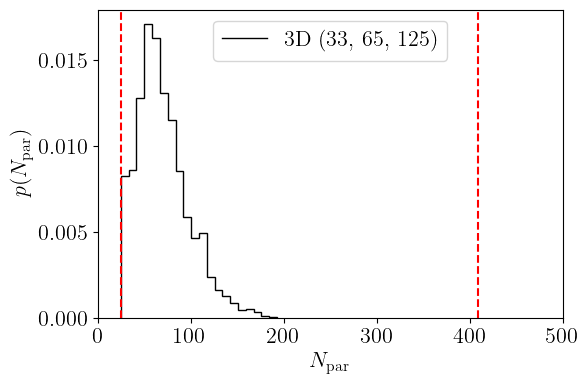

In [11]:
fig, ax = plt.subplots(figsize=(6,4))
ax.set(
    yscale="linear",
    xlabel=r"$N_{\mathrm{par}}$",
    ylabel=r"$p(N_{\mathrm{par}})$",
    xlim=(0, 500),
)

ls = ["-", "--", ":"]

ind=0
ndim=3
offset=2**ndim

n_params = tri_sizes * (ndim + 1) + offset + 1

l, m, h = np.quantile(n_params, [0.05, 0.5, 0.95]).astype(int)

hist, edges = np.histogram(n_params, density=True, bins=20)
ax.stairs(
    hist,
    edges, 
    color='black', 
    ls=ls[ind], 
    label=f"{ndim}D ({l}, {m}, {h})"
)

ax.axvline(nvertices_min * (ndim + 1) + offset + 1, color='r', linestyle='--')
ax.axvline(nvertices_max * (ndim + 1) + offset + 1, color='r', linestyle='--')

ax.legend()
plt.show()
plt.close()

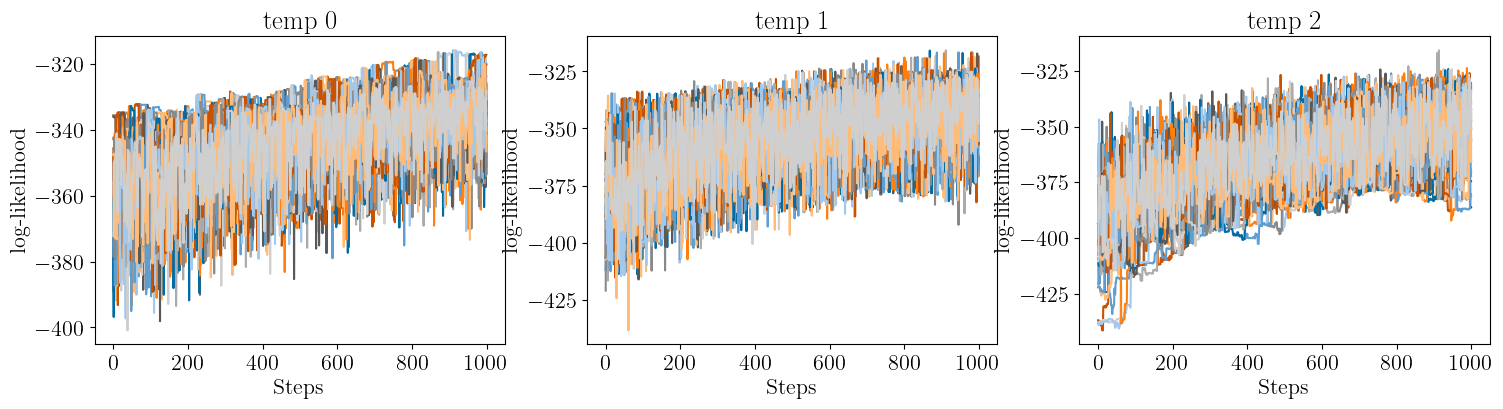

In [12]:
fig, axes = plt.subplots(1, ntemps, figsize=(18,4))
for t,w in product(range(ntemps),range(nwalkers)):
    ax = axes[t]
    ax.plot(back.get_log_like()[:, t, w])
    ax.set(title=f"temp {t}")
    ax.set_xlabel(r"Steps")
    ax.set_ylabel(r"log-likelihood")
plt.show()
plt.close()

In [13]:
nburn = 750

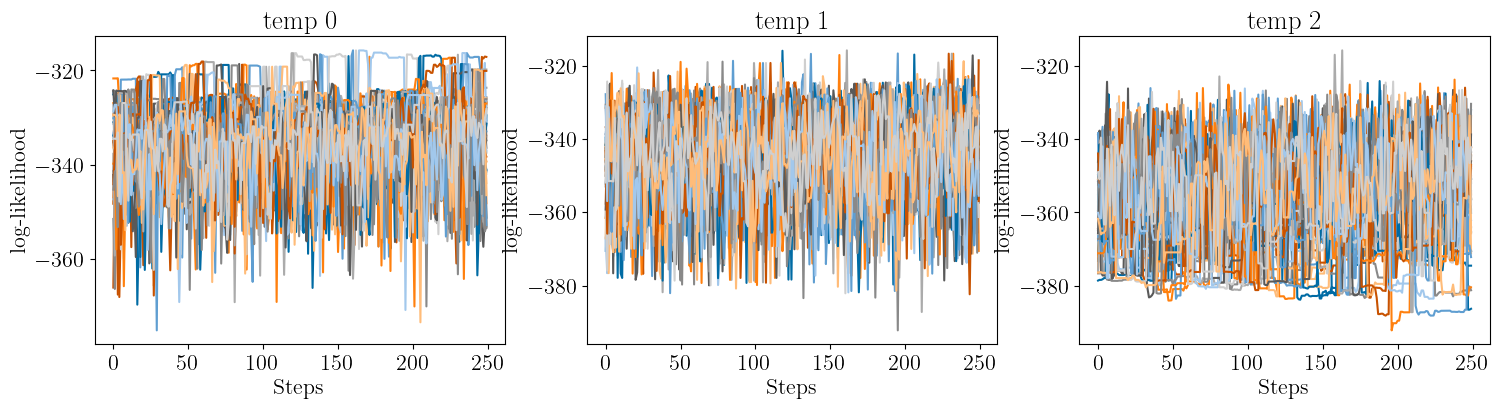

In [14]:
fig, axes = plt.subplots(1, ntemps, figsize=(18,4))
for t,w in product(range(ntemps),range(nwalkers)):
    ax = axes[t]
    ax.plot(back.get_log_like()[nburn:, t, w])
    ax.set(title=f"temp {t}")
    ax.set_xlabel(r"Steps")
    ax.set_ylabel(r"log-likelihood")
plt.show()
plt.close()

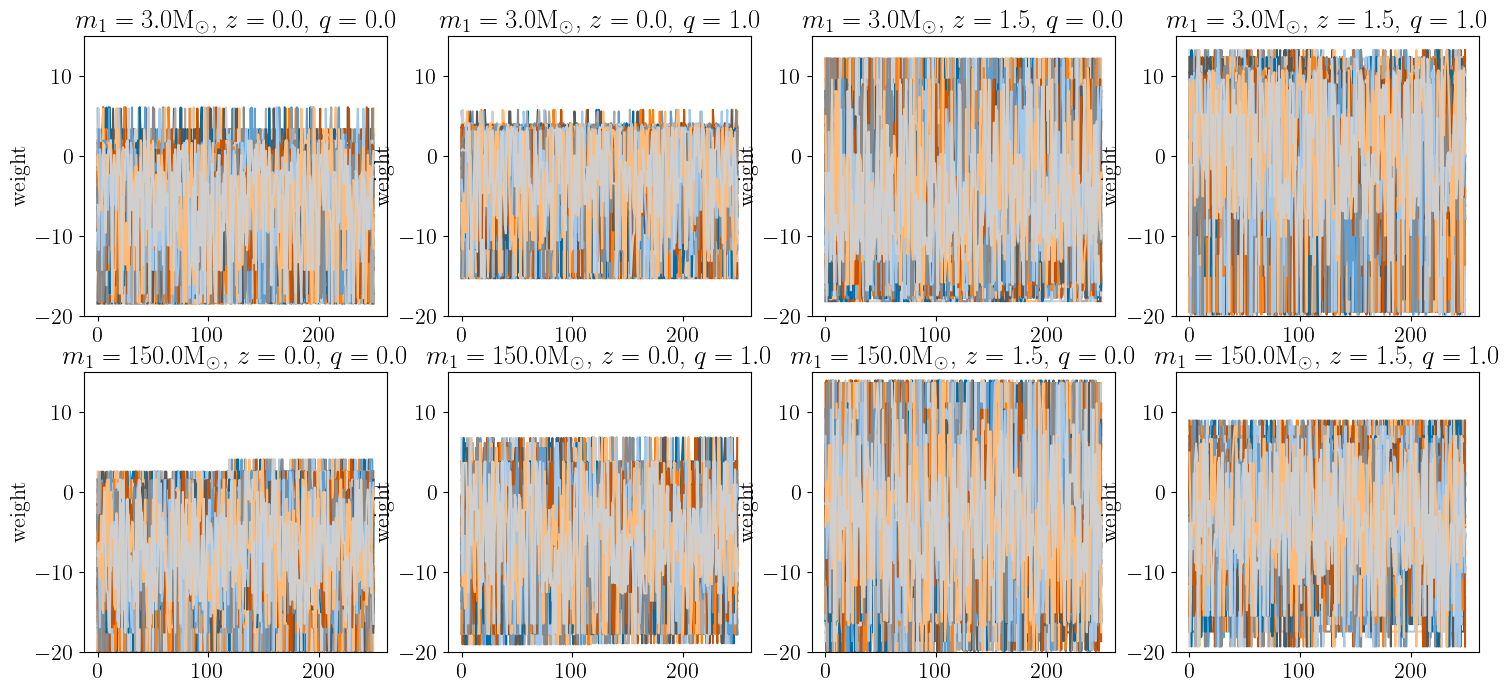

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(18,8))
for n in range(len(corners)):
    ax = axes[n//4, n%4]
    for t,w in product(range(ntemps-1),range(nwalkers)):
        ax.plot(np.ravel(back.chain['corner_w'][nburn:,t,w,0,n]))
    # t=0
    # for w in range(nwalkers):
    #     ax.plot(np.ravel(back.chain['corner_w'][nburn:,t,w,0,n]))
    ax.set(title=r"$m_1=%.1f\mathrm{M}_\odot$, $z=%.1f$, $q=%.1f$" 
           %(corners[n][0],corners[n][1],corners[n][2]))
    #ax.set_xlabel(r"Steps")
    ax.set_ylabel(r"weight")
    ax.set_ylim(w_min,w_max)
plt.show()
plt.close()

## Load triangulations

In [16]:
all_triangulations = []
# for t in range(ntemps):
#     triangulations = [
#         back.chain["tri"][step, t, walker][back.inds["tri"][step, t, walker]]
#         for step, walker in product(range(nburn,nsteps), range(nwalkers))
#     ]
#     corner_weights = np.array(
#         [
#             back.chain["corner_w"][step, t, walker]
#             for step, walker in product(range(nburn,nsteps), range(nwalkers))
#         ]
#     )
#     for ind in tqdm(range(len(triangulations))):
#         all_triangulations.extend([
#             np.vstack([triangulations[ind], np.c_[corners, corner_weights[ind].T]])                
#         ])
### KEEP ONLY FIRST TEMPERATURE FOR NOW ###
t=0
triangulations = [
    back.chain["tri"][step, t, walker][back.inds["tri"][step, t, walker]]
    for step, walker in product(range(nburn,nsteps), range(nwalkers))
]
corner_weights = np.array(
    [
        back.chain["corner_w"][step, t, walker]
        for step, walker in product(range(nburn,nsteps), range(nwalkers))
    ]
)
for ind in tqdm(range(len(triangulations))):
    all_triangulations.extend([
        np.vstack([triangulations[ind], np.c_[corners, corner_weights[ind].T]])                
    ])

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████| 10000/10000 [00:00<00:00, 217592.03it/s]


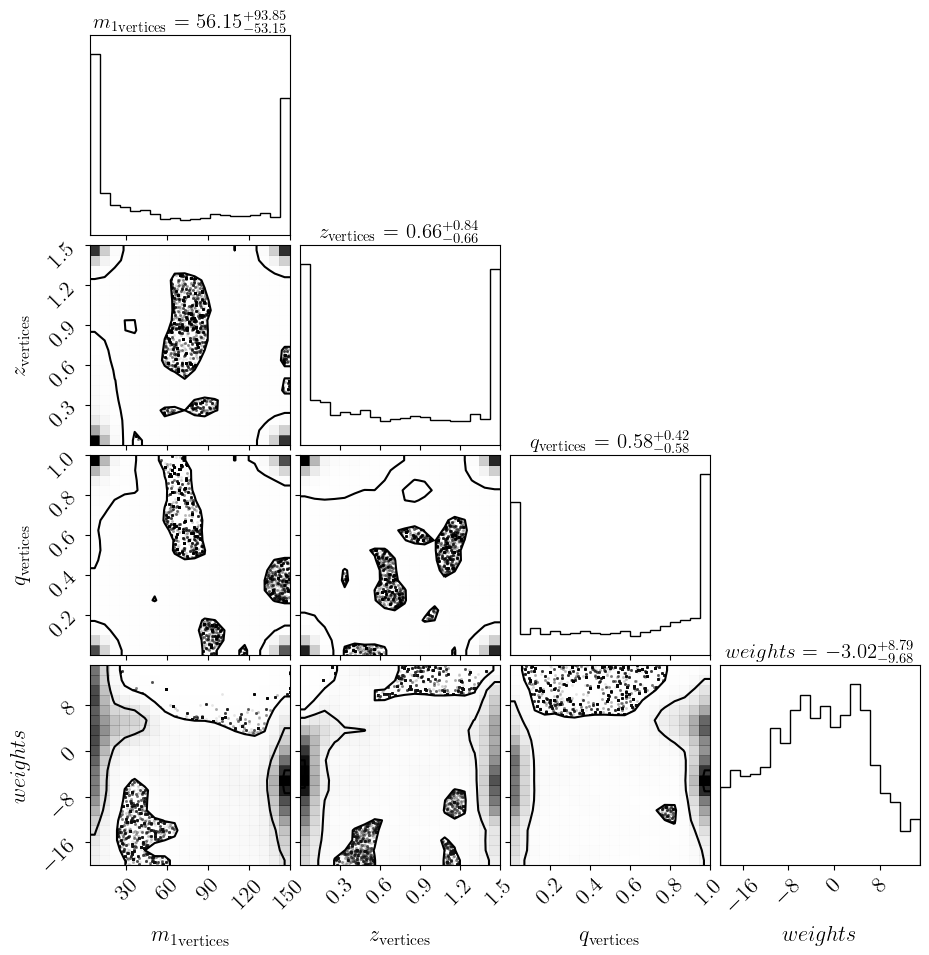

In [17]:
ws = np.hstack([tri[:, -1] for tri in all_triangulations])
vertices = np.vstack([tri[:, :-1] for tri in all_triangulations])    
corner_plot(np.c_[vertices, ws], smooth=True, levels=[0.05, 0.5, 0.95],
            labels=[r"${m_1}_\mathrm{vertices}$", r"$z_\mathrm{vertices}$", r"$q_\mathrm{vertices}$", r"$weights$"],
            show_titles=True,
            title_kwargs={"fontsize": 15},
           )
plt.show()
plt.close()

In [18]:
## Evolution of the inferred rate at fixed points ##
targets = np.array([[10.,0.2,0.8],[35.,0.2,0.8],[35.,1.0,0.8],[35.,0.2,0.5]])
selected_tris = np.random.choice(len(all_triangulations), size=5_000, replace=False)
num_triangulations = len(selected_tris)

log_rate_at_target = np.zeros((num_triangulations,4))

for ind, tri_ind in enumerate(tqdm(selected_tris)):
    this_delo = delaunaytor.CPUDelaunayInterpolator()
    this_delo.triangulate(all_triangulations[tri_ind])
    log_rate_at_target[ind] = this_delo.interpolate(targets)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████| 5000/5000 [00:03<00:00, 1526.89it/s]


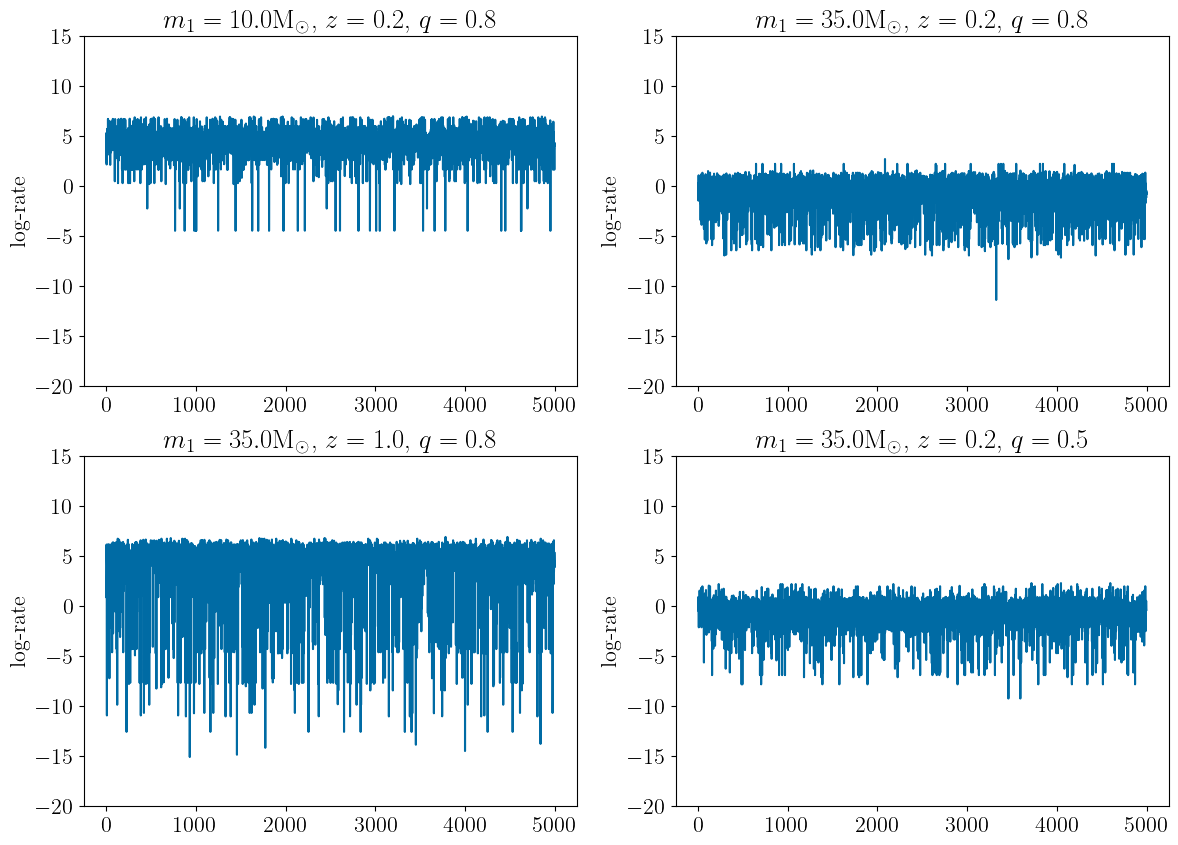

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14,10))
for n in range(len(targets)):
    ax = axes[n//2, n%2]
    ax.plot(log_rate_at_target[:,n])
    ax.set(title=r"$m_1=%.1f\mathrm{M}_\odot$, $z=%.1f$, $q=%.1f$" 
           %(targets[n][0],targets[n][1],targets[n][2]))
    #ax.set_xlabel(r"Steps")
    ax.set_ylabel(r"log-rate")
    ax.set_ylim(w_min,w_max)
plt.show()
plt.close()

## Compute rate over grids

In [20]:
m1_grid = np.linspace(m1_min, m1_max, 148)
z_grid = np.linspace(0.1, z_max, 71) # starts at 0.1 instead of 0 to avoid the divergence of differential comoving volume
q_grid = np.linspace(q_min, q_max, 51)
dm1 = m1_grid[1] - m1_grid[0]
dq = q_grid[1] - q_grid[0]
dz = z_grid[1] - z_grid[0]

### Injections

In [21]:
injections_file = np.load("../gwax_samples/gwtc4_injections_full.npz")
detected_injections = np.vstack(
    [injections_file[key + "s"] for key in parameter_keys]
).T
injection_priors = injections_file["inj_priors"]
num_injections = int(injections_file["ninjs"])
Tobs = injections_file['analysis_time'] # in years

In [22]:
print('Total time of the combined runs: %.3f years' %Tobs)
print('Total number of injections for GWTC-3: %.2e' %num_injections)
print('Number of detected injections for GWTC-3: %.2e' %detected_injections.shape[0])

Total time of the combined runs: 2.123 years
Total number of injections for GWTC-3: 1.13e+09
Number of detected injections for GWTC-3: 1.07e+06


# Marginals

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████| 5000/5000 [00:07<00:00, 667.80it/s]


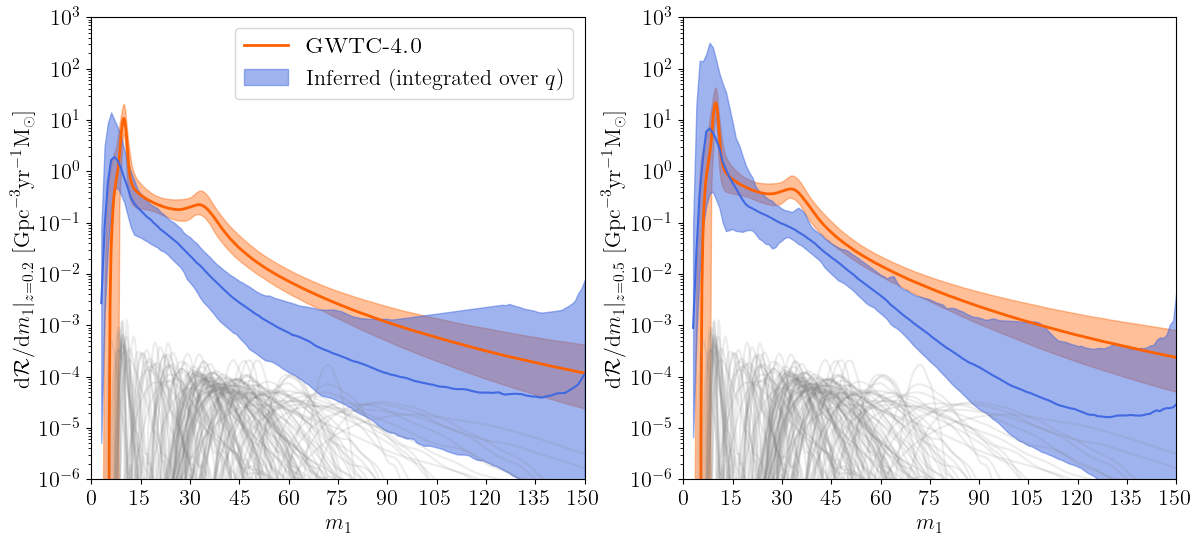

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14,6))

z_values_toplot = [0.2,0.5]
ymins = [1e-6, 1e-6]
ymaxs = [1e3, 1e3]

for n,zeval in enumerate(z_values_toplot):
    ax = axes[n]
    renorm = ((1+zeval)/(1+0.2))**kappas
    pf.plot_90CI(ax, bptp_m1, bptp_m1_pdfs * renorm[:,None], 
             color=color1,  fill_alpha=0.4,
             label=r'\textsc{GWTC-4.0}',
            )
    
    ## m1 posterior of all mock events ##
    for k in range(num_events):
        m1_event_k = observed_events[k*num_samples:(k+1)*num_samples,0]
        kernel = gaussian_kde(m1_event_k)
        ax.plot(bptp_m1, 1e-3*kernel(bptp_m1),
                c='gray', alpha=0.15,
               )
        
    ## Compute log-rate over a grid with fixed redshift ##    
    X0, Y0, Z0 = np.meshgrid(m1_grid, np.array([zeval]), q_grid)
    grid0 = np.c_[X0.ravel(), Y0.ravel(), Z0.ravel()]

    toRate_at_zeval = (1 + zeval) / (
        4 * np.pi * Tobs * Planck15.differential_comoving_volume(zeval).to(u.Gpc**3 / u.sr).value
    )
    
    log_rate = np.zeros((num_triangulations, grid0.shape[0]))
    for ind, tri_ind in enumerate(tqdm(selected_tris)):
        this_delo = delaunaytor.CPUDelaunayInterpolator()
        this_delo.triangulate(all_triangulations[tri_ind])
        log_rate[ind] = this_delo.interpolate(grid0)
        
    log_d2N_dm1dq = log_rate.reshape(num_triangulations, m1_grid.shape[0], q_grid.shape[0])
    dNdm1_zeval = np.sum(np.exp(log_d2N_dm1dq), axis=2) *dq
    dRdm1_zeval = dNdm1_zeval *toRate_at_zeval
    
    low_dRdm1 = np.quantile(dRdm1_zeval, 0.05, axis=0)
    median_dRdm1 = np.quantile(dRdm1_zeval, 0.5, axis=0)
    high_dRdm1 = np.quantile(dRdm1_zeval, 0.95, axis=0)
    
    ax.plot(m1_grid, median_dRdm1, color="royalblue")
    ax.fill_between(m1_grid, low_dRdm1, high_dRdm1,
                    color="royalblue", alpha=0.5,
                    label=r'Inferred (integrated over $q$)',
                    )
    
    ax.set_xlabel(r'$m_1$')
    ax.set_xlim(xmin=m1_min, xmax=m1_max)
    ax.set_xticks(np.linspace(0,m1_max,int(m1_max/15)+1))
    ax.set_ylabel(r'$\mathrm{d}\mathcal{R}/\mathrm{d}m_1 |_{z=%.1f}\ [\mathrm{Gpc}^{-3}\mathrm{yr}^{-1}\mathrm{M}_\odot]$' %zeval)
    ax.set_yscale('log')
    #ax.set_box_aspect(1)
    ax.set_ylim(ymin=ymins[n], ymax=ymaxs[n])

axes[0].legend(loc='best')
plt.show()
plt.close()

In [24]:
## Compute log-rate over full (reduced) 3D grid ##
m1_grid0 = np.linspace(m1_min, m1_max, 50)
z_grid0 = np.linspace(0.1, z_max, 15) # starts at 0.1 instead of 0 to avoid the divergence of differential comoving volume
q_grid0 = np.linspace(q_min, q_max, 21)
dm10 = m1_grid0[1] - m1_grid0[0]
dq0 = q_grid0[1] - q_grid0[0]
dz0 = z_grid0[1] - z_grid0[0]

X0, Y0, Z0 = np.meshgrid(m1_grid0, z_grid0, q_grid0)
grid0 = np.c_[X0.ravel(), Y0.ravel(), Z0.ravel()]

toRate = (1 + z_grid0) / (
    4 * np.pi * Tobs * Planck15.differential_comoving_volume(z_grid0).to(u.Gpc**3 / u.sr).value
)

log_rate = np.zeros((num_triangulations, grid0.shape[0]))
for ind, tri_ind in enumerate(tqdm(selected_tris)):
    this_delo = delaunaytor.CPUDelaunayInterpolator()
    this_delo.triangulate(all_triangulations[tri_ind])
    log_rate[ind] = this_delo.interpolate(grid0)
    
log_d2N_dzdm1dq = log_rate.reshape(num_triangulations, z_grid0.shape[0], m1_grid0.shape[0], q_grid0.shape[0])
dNdz = np.sum(np.exp(log_d2N_dzdm1dq), axis=(2,3)) *dm10 *dq0
Rz = dNdz *toRate

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████| 5000/5000 [00:13<00:00, 374.74it/s]


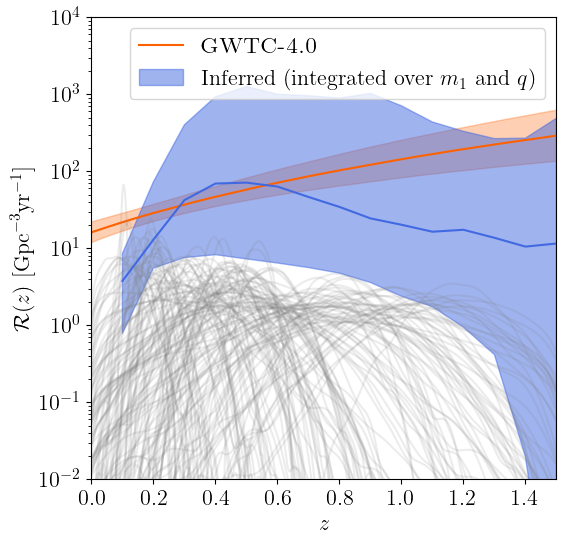

In [25]:
fig, ax = plt.subplots(1, 1, figsize=(6,6))


ax.fill_between(z_list_gwtc4, np.percentile(R_z_gwtc4, 5, axis=0), np.percentile(R_z_gwtc4, 95, axis=0), 
                color=color1, alpha=0.3,
               )
ax.plot(z_list_gwtc4, np.percentile(R_z_gwtc4, 50, axis=0), 
        color=color1, 
        label=r'\textsc{ GWTC-4.0}',
       )

## z posterior of all mock events ##
for k in range(num_events):
    z_event_k = observed_events[k*num_samples:(k+1)*num_samples,1]
    kernel = gaussian_kde(z_event_k)
    ax.plot(z_list_gwtc4, kernel(z_list_gwtc4),
            c='gray', alpha=0.15,
           )

low_Rz = np.quantile(Rz, 0.05, axis=0)
median_Rz = np.quantile(Rz, 0.5, axis=0)
high_Rz = np.quantile(Rz, 0.95, axis=0)

ax.plot(z_grid0, median_Rz, color="royalblue")
ax.fill_between(z_grid0, low_Rz, high_Rz,
                color="royalblue", alpha=0.5,
                label=r'Inferred (integrated over $m_1$ and $q$)',
                )
    

ax.set_xlabel(r'$z$')
ax.set_xlim(xmin=z_min, xmax=z_max)
ax.set_xticks(np.linspace(0,z_max,int(z_max*10)+1)[::2])
ax.set_ylabel(r'$\mathcal{R}(z)\ [\mathrm{Gpc}^{-3}\mathrm{yr}^{-1}]$')
ax.set_yscale('log')
ax.legend(loc='best')
#ax.set_box_aspect(1)
ax.set_ylim(ymin=1e-2, ymax=1e4)

plt.show()
plt.close()